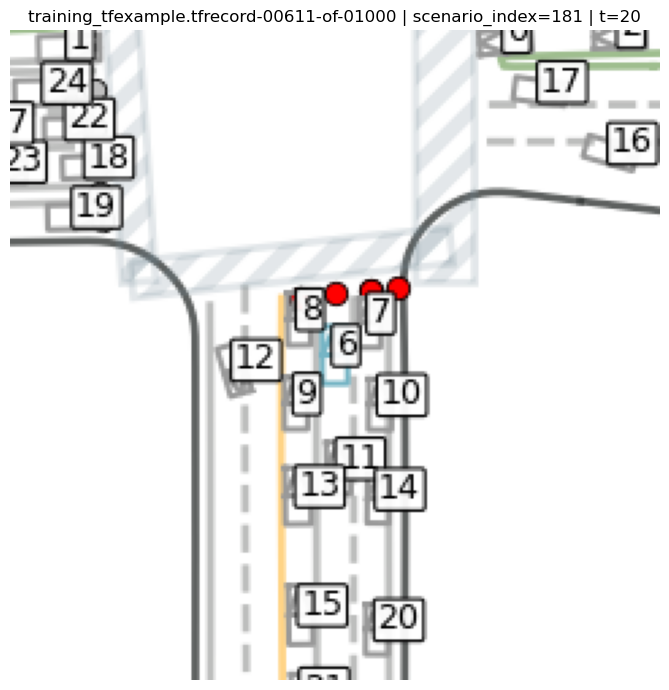

Selected source file: /data/user_data/yixiz/autonlab/zfsauton/scratch/mineuih/waymax_rs/annotations/training_tfexample.tfrecord-00611-of-01000_t20.jsonl
Selected source line: 182
Selected timestep for visualization: 20

Matched annotation file: /data/user_data/yixiz/autonlab/zfsauton/scratch/mineuih/waymax_rs/annotations/training_tfexample.tfrecord-00611-of-01000_t20.jsonl
Matched annotation line: 182

Pretty JSON:
{
  "annotation": {
    "ego_motion": {
      "end_xy": [
        -0.0,
        -0.0
      ],
      "end_yaw": 0.0,
      "start_speed": 0.0,
      "end_speed": 0.0,
      "avg_speed": 0.0,
      "direction": "right",
      "turn_label": "straight",
      "lane_change": "none"
    },
    "lane_context": {
      "left_lane": "exist",
      "right_lane": "exist",
      "traffic_lights": {
        "straight": "stop"
      }
    },
    "vehicles": {
      "rear": {
        "relative_position": [
          -10.4,
          -0.3
        ],
        "speed": 2.0,
        "distance":

In [ ]:
from pathlib import Path
import copy
import json
import random
import re
import sys

import matplotlib.pyplot as plt
import numpy as np
import os
os.environ["JAX_PLATFORMS"] = "cpu"
os.environ["JAX_PLATFORM_NAME"] = "cpu"

repo_root = Path.cwd()
if not (repo_root / "README.md").exists():
    repo_root = Path("/data/user_data/yixiz/autonlab/zfsauton2/home/mineuih/waymax_rs")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from viz import viz as viz_module

tfrecord_dir = Path("/data/user_data/yixiz/autonlab/zfsauton/scratch/eshau/womd/tf_example/training")
annotations_dir = Path("/data/user_data/yixiz/autonlab/zfsauton/scratch/mineuih/waymax_rs/annotations")
cache_dir = Path("/data/user_data/yixiz/autonlab/zfsauton/scratch/mineuih/waymax_rs/sim_state_cache_npz")
timesteps = [10, 20, 30, 40, 50, 60, 70, 80]


def pick_random_nonempty_line(file_path: Path):
    chosen_line_no = None
    chosen_line = None
    seen = 0

    with file_path.open("r", encoding="utf-8") as handle:
        for line_no, line in enumerate(handle, start=1):
            line = line.strip()
            if not line:
                continue
            seen += 1
            if random.randint(1, seen) == 1:
                chosen_line_no = line_no
                chosen_line = line

    if chosen_line is None:
        raise ValueError(f"No non-empty lines found in {file_path}")

    return chosen_line_no, chosen_line


SIM_STATE_CACHE_FIELDS = {
    "object_metadata": {
        "is_sdc": "object_metadata_is_sdc",
        "object_types": "object_metadata_object_types",
    },
    "log_trajectory": {
        "x": "log_trajectory_x",
        "y": "log_trajectory_y",
        "yaw": "log_trajectory_yaw",
        "length": "log_trajectory_length",
        "width": "log_trajectory_width",
        "valid": "log_trajectory_valid",
        "vel_x": "log_trajectory_vel_x",
        "vel_y": "log_trajectory_vel_y",
        "speed": "log_trajectory_speed",
    },
    "log_traffic_light": {
        "state": "log_traffic_light_state",
        "x": "log_traffic_light_x",
        "y": "log_traffic_light_y",
        "lane_ids": "log_traffic_light_lane_ids",
        "valid": "log_traffic_light_valid",
    },
    "roadgraph_points": {
        "ids": "roadgraph_points_ids",
        "types": "roadgraph_points_types",
        "valid": "roadgraph_points_valid",
        "x": "roadgraph_points_x",
        "y": "roadgraph_points_y",
        "dir_x": "roadgraph_points_dir_x",
        "dir_y": "roadgraph_points_dir_y",
    },
}


class _Group:
    pass


def _to_world_first(array: np.ndarray) -> np.ndarray:
    return np.expand_dims(np.asarray(array), axis=0)


def _scenario_from_cache(npz_data: np.lib.npyio.NpzFile, scenario_pos: int):
    sim_state = _Group()
    for group_name, attributes in SIM_STATE_CACHE_FIELDS.items():
        group_obj = _Group()
        for attr_name, field_name in attributes.items():
            setattr(group_obj, attr_name, _to_world_first(npz_data[field_name][scenario_pos]))
        setattr(sim_state, group_name, group_obj)
    return sim_state


def _drop_batch_dim(sim_state):
    unbatched = _Group()
    for group_name, attributes in SIM_STATE_CACHE_FIELDS.items():
        group_obj = _Group()
        batched_group = getattr(sim_state, group_name)
        for attr_name in attributes.keys():
            value = np.asarray(getattr(batched_group, attr_name))
            setattr(group_obj, attr_name, value[0] if value.shape[:1] == (1,) else value)
        if group_name == "log_trajectory":
            group_obj.xy = np.stack([np.asarray(group_obj.x), np.asarray(group_obj.y)], axis=-1)
            group_obj.vel_xy = np.stack([np.asarray(group_obj.vel_x), np.asarray(group_obj.vel_y)], axis=-1)
            group_obj.shape = np.asarray(group_obj.x).shape[:2]
            group_obj.num_objects = int(np.asarray(group_obj.x).shape[0])
            group_obj.stack_fields = lambda fields, group_obj=group_obj: np.stack(
                [np.asarray(getattr(group_obj, field)) for field in fields], axis=-1
            )
        elif group_name == "log_traffic_light":
            group_obj.xy = np.stack([np.asarray(group_obj.x), np.asarray(group_obj.y)], axis=-1)
            group_obj.shape = np.asarray(group_obj.valid).shape
        elif group_name == "roadgraph_points":
            group_obj.xy = np.stack([np.asarray(group_obj.x), np.asarray(group_obj.y)], axis=-1)
            group_obj.shape = np.asarray(group_obj.valid).shape[:1]
        elif group_name == "object_metadata":
            group_obj.shape = np.asarray(group_obj.is_sdc).shape
            group_obj.num_objects = int(np.asarray(group_obj.is_sdc).shape[0])
        setattr(unbatched, group_name, group_obj)
    unbatched.shape = ()
    return unbatched


def load_scenario_state_from_cache(cache_dir: Path, tfrecord_name: str, scenario_index: int):
    cache_path = cache_dir / f"{tfrecord_name}.sim_state_cache.npz"
    if not cache_path.exists():
        raise FileNotFoundError(f"Cache file not found: {cache_path}")

    with np.load(cache_path, allow_pickle=True) as cache_npz:
        scenario_indices = np.asarray(cache_npz["scenario_indices"]).astype(np.int32)
        matches = np.flatnonzero(scenario_indices == int(scenario_index))
        if matches.size == 0:
            raise FileNotFoundError(f"scenario_index {scenario_index} not found in cache {cache_path}")
        return _drop_batch_dim(_scenario_from_cache(cache_npz, int(matches[0])))


def clone_with_timestep(sim_state, timestep: int):
    cloned = copy.deepcopy(sim_state)
    cloned.timestep = int(timestep)
    return cloned


jsonl_files = sorted(annotations_dir.glob("*.jsonl"))
if not jsonl_files:
    raise FileNotFoundError(f"No .jsonl files found in {annotations_dir.resolve()}")

selected_file = random.choice(jsonl_files)
selected_line_no, selected_line_text = pick_random_nonempty_line(selected_file)
selected_record = json.loads(selected_line_text)

tfrecord_name = selected_record["tfrecord_path"]
scenario_index = int(selected_record["scenario_index"])
tfrecord_path = tfrecord_dir / tfrecord_name
if not tfrecord_path.exists():
    raise FileNotFoundError(f"TFRecord not found: {tfrecord_path}")

sim_state = load_scenario_state_from_cache(cache_dir, tfrecord_name, scenario_index)

selected_timestep_match = re.search(r"_t(\d+)\.jsonl$", selected_file.name)
if selected_timestep_match is not None:
    selected_timestep = int(selected_timestep_match.group(1))
else:
    selected_timestep = next((t for t in timesteps if t < int(np.asarray(sim_state.log_trajectory.x).shape[-1])), 0)

num_steps = int(np.asarray(sim_state.log_trajectory.x).shape[-1])
if not 0 <= selected_timestep < num_steps:
    selected_timestep = max(0, min(selected_timestep, num_steps - 1))

viz_config = {
    "show_agent_id": True,
    "center_agent_idx": -1,
    "front_x": 30.0,
    "back_x": 30.0,
    "front_y": 30.0,
    "back_y": 30.0,
    "px_per_meter": 4.0,
}

state_t = clone_with_timestep(sim_state, selected_timestep)
frame = viz_module.plot_simulator_state(state_t, use_log_traj=True, viz_config=viz_config, batch_idx=-1)

plt.figure(figsize=(7, 7))
plt.imshow(frame)
plt.title(f"{tfrecord_name} | scenario_index={scenario_index} | t={selected_timestep}")
plt.axis("off")
plt.tight_layout()
plt.show()

matched_file, matched_line_no, matched_record = selected_file, selected_line_no, selected_record

print(f"Selected source file: {selected_file}")
print(f"Selected source line: {selected_line_no}")
print(f"Selected timestep for visualization: {selected_timestep}")
print(f"\nMatched annotation file: {matched_file}")
print(f"Matched annotation line: {matched_line_no}")
print("\nPretty JSON:")

def format_scalar(value):
    if isinstance(value, bool):
        return value
    if isinstance(value, np.generic):
        value = value.item()
    if isinstance(value, (int, float)) and not isinstance(value, bool):
        return round(float(value), 1)
    return value


def format_value(key, value):
    if key in {"tfrecord_path", "scenario_index", "scenario_window", "object_index", "lane_id", "lane_ids", "start_lane_id", "end_lane_id", "left_lane_ids", "right_lane_ids"}:
        return None
    if key == "lane_context" and isinstance(value, dict):
        left_lane_ids = value.get("left_lane_ids", [])
        right_lane_ids = value.get("right_lane_ids", [])
        formatted_lane_context = {
            "left_lane": "exist" if len(left_lane_ids) >= 1 else "none",
            "right_lane": "exist" if len(right_lane_ids) >= 1 else "none",
        }
        if "traffic_lights" in value:
            formatted_lane_context["traffic_lights"] = format_value("traffic_lights", value.get("traffic_lights", {}))
        return formatted_lane_context
    if isinstance(value, dict):
        formatted = {}
        for subkey, subvalue in value.items():
            formatted_value = format_value(subkey, subvalue)
            if formatted_value is not None:
                formatted[subkey] = formatted_value
        return formatted
    if isinstance(value, list):
        return [format_value(key, item) if isinstance(item, (dict, list)) else format_scalar(item) for item in value]
    return format_scalar(value)


filtered_record = {
    "annotation": format_value("annotation", matched_record.get("annotation", {})),
    "instruction": matched_record.get("instruction"),
}
print(json.dumps(filtered_record, indent=2, ensure_ascii=False))


def _jsonable(value):
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, tuple):
        return list(value)
    return value


def _as_mapping(value):
    if isinstance(value, dict):
        return value
    if isinstance(value, list) and value and isinstance(value[0], dict):
        return value[0]
    return {}


def build_gemma_reasoning_prompt(record: dict) -> str:
    annotation = _as_mapping(record.get("annotation", {})) if isinstance(record, dict) else {}
    instruction = record.get("instruction", "") if isinstance(record, dict) else ""
    lane_context = _as_mapping(annotation.get("lane_context", {}))
    traffic_lights = _as_mapping(lane_context.get("traffic_lights", {}))
    vehicles = _as_mapping(annotation.get("vehicles", {}))
    ego_motion = _as_mapping(annotation.get("ego_motion", {}))
    goal_info = _as_mapping(annotation.get("goal_info", {}))

    examples = [
        "lane_context.left_lane_ids = [] -> there is no usable lane on the left side of ego.",
        f"lane_context.traffic_lights.straight = {traffic_lights.get('straight', 'unknown')!r} -> the straight-through signal can support stopping or proceeding.",
        f"vehicles.front = {_jsonable(vehicles.get('front'))!r} -> a vehicle ahead may constrain speed or lane choice.",
        f"goal_info.relative_position = {_jsonable(goal_info.get('relative_position', 'unknown'))!r} -> the goal direction is expressed in the ego frame.",
        f"ego_motion = {_jsonable(ego_motion)!r} -> this summarizes the target maneuver and speed change.",
    ]

    prompt_lines = [
        "You are given one driving scene image and one annotation JSON record.",
        "Your task is to explain, in natural language, why the ego vehicle should perform the target instruction.",
        "",
        "Annotation meaning guide:",
        "- lane_context.left_lane_ids / right_lane_ids: adjacent lane IDs on each side of the ego vehicle. An empty list means there is no lane on that side.",
        "- lane_context.traffic_lights: traffic-light states for the relevant movement directions. Common values include go, stop, caution, arrow_go, arrow_stop, flashing_stop, and unknown.",
        "- vehicles.front / rear / front_left / rear_left / front_right / rear_right: the nearest vehicle in that relative region, or null when none exists. Distance and speed describe how close and how fast the object is.",
        "- risk_objects: pedestrians or vehicles that may impede ego progress.",
        "- ego_motion: target motion label. start_speed and end_speed describe the speed change; direction, turn_label, and lane_change describe the planned maneuver.",
        "- goal_info.relative_position: goal location relative to the ego vehicle. Positive x is forward, positive y is left.",
        "- instruction: the target next ego action that the model should explain.",
        "",
        "Examples:",
        *[f"- {example}" for example in examples],
        "",
        "Task:",
        f"Write a concise rationale for why the ego vehicle should perform this target instruction: {instruction!r}.",
        "Use the image and the annotation together.",
        "Mention lane availability, traffic signals, nearby vehicles or pedestrians, ego speed, and goal direction only when relevant.",
        "Do not invent facts that are not supported by the image or the annotation.",
        "Return only the rationale text, 2-4 sentences long.",
    ]

    return "\n".join(prompt_lines)


source_record = matched_record
gemma_reasoning_prompt = build_gemma_reasoning_prompt(source_record)

print("\nGemma reasoning prompt:\n")
print(gemma_reasoning_prompt)

In [ ]:
# Call the separate vLLM server instead of loading Gemma in this notebook.
# Start the server first, for example:
# CUDA_VISIBLE_DEVICES=1 python scripts/vllm.py --model-name google/gemma-4-31b-it --port 8001

import base64
import io

import requests
from PIL import Image

SERVER_URL = "http://127.0.0.1:8001/generate"
SERVER_HEALTH_URL = "http://127.0.0.1:8001/health"

def encode_image_to_base64(image) -> str:
    buffer = io.BytesIO()
    image.save(buffer, format="PNG")
    return base64.b64encode(buffer.getvalue()).decode("utf-8")

image = Image.fromarray(np.asarray(frame).astype(np.uint8)).convert("RGB")
image_base64 = encode_image_to_base64(image)
prompt_text = gemma_reasoning_prompt

try:
    health_response = requests.get(SERVER_HEALTH_URL, timeout=10)
    health_response.raise_for_status()
except requests.RequestException as exc:
    raise RuntimeError(
        f"Unable to reach the vLLM server at {SERVER_HEALTH_URL}. Start scripts/vllm.py first, then rerun this cell. Original error: {exc}"
    ) from exc

payload = {
    "prompt": prompt_text,
    "image_base64": image_base64,
    "temperature": 0.2,
    "top_p": 0.9,
    "max_tokens": 256,
}

response = requests.post(SERVER_URL, json=payload, timeout=300)
response.raise_for_status()
answer_text = response.json()["text"].strip()

print("Gemma-4-31B answer from vLLM server:\n")
print(answer_text)


INFO 07-01 15:38:21 [utils.py:240] non-default args: {'trust_remote_code': True, 'dtype': 'bfloat16', 'max_model_len': 8192, 'gpu_memory_utilization': 0.7, 'disable_log_stats': True, 'limit_mm_per_prompt': {'image': 1}, 'model': 'google/gemma-4-31b-it'}
INFO 07-01 15:38:22 [model.py:568] Resolved architecture: Gemma4ForConditionalGeneration
INFO 07-01 15:38:22 [model.py:1697] Using max model len 8192
INFO 07-01 15:38:22 [scheduler.py:239] Chunked prefill is enabled with max_num_batched_tokens=8192.
INFO 07-01 15:38:22 [config.py:101] Gemma4 model has heterogeneous head dimensions (head_dim=256, global_head_dim=512). Forcing TRITON_ATTN backend to prevent mixed-backend numerical divergence.
INFO 07-01 15:38:22 [vllm.py:886] Asynchronous scheduling is enabled.
INFO 07-01 15:38:22 [kernel.py:212] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'])
WARNING 07-01 15:38:22 [cuda.py:237] Forcing --disable_chunked_mm_inpu

(EngineCore pid=26798) Process EngineCore:
(EngineCore pid=26798) Traceback (most recent call last):
(EngineCore pid=26798)   File "/data/user_data/yixiz/autonlab/zfsauton/scratch/mineuih/conda_envs/waymax_rs/lib/python3.12/multiprocessing/process.py", line 314, in _bootstrap
(EngineCore pid=26798)     self.run()
(EngineCore pid=26798)   File "/data/user_data/yixiz/autonlab/zfsauton/scratch/mineuih/conda_envs/waymax_rs/lib/python3.12/multiprocessing/process.py", line 108, in run
(EngineCore pid=26798)     self._target(*self._args, **self._kwargs)
(EngineCore pid=26798)   File "/data/user_data/yixiz/autonlab/zfsauton/scratch/mineuih/conda_envs/waymax_rs/lib/python3.12/site-packages/vllm/v1/engine/core.py", line 1144, in run_engine_core
(EngineCore pid=26798)     raise e
(EngineCore pid=26798)   File "/data/user_data/yixiz/autonlab/zfsauton/scratch/mineuih/conda_envs/waymax_rs/lib/python3.12/site-packages/vllm/v1/engine/core.py", line 1114, in run_engine_core
(EngineCore pid=26798)     e

RuntimeError: Failed to initialize vLLM for google/gemma-4-31b-it. This usually means the selected GPU does not have enough free memory, the model id is unavailable, or the local vLLM installation is incompatible. Original error: Engine core initialization failed. See root cause above. Failed core proc(s): {}